In [10]:
import pandas as pd
import numpy as np
from scipy.stats import wilcoxon

df = pd.read_csv("/content/N3_N4_wilcoxon.csv")

N3 = df.iloc[:, 1:6].to_numpy()
N4 = df.iloc[:, 6:11].to_numpy()

print("N3:", N3.shape)
print("N4:", N4.shape)

N3: (225, 5)
N4: (225, 5)


In [11]:
print("N3 - Primeiras 5 instâncias:")
print(N3[:5])

print("\nN4 - Primeiras 5 instâncias:")
print(N4[:5])

print("\nValores ausentes em N3:", np.isnan(N3).sum())
print("Valores ausentes em N4:", np.isnan(N4).sum())

print("\nTotal de resultados N3:", N3.size)
print("Total de resultados N4:", N4.size)

N3 - Primeiras 5 instâncias:
[[27.949 27.282 28.507 27.881 26.712]
 [13.535 13.331 14.258 13.502 14.047]
 [26.548 27.998 26.208 27.462 25.848]
 [27.182 24.977 26.97  25.714 25.654]
 [28.61  29.491 29.15  27.292 29.148]]

N4 - Primeiras 5 instâncias:
[[26.639 26.467 26.541 26.728 26.808]
 [14.636 14.294 13.827 14.414 14.456]
 [24.279 24.623 24.471 24.52  24.544]
 [24.208 24.501 24.189 24.75  24.733]
 [27.632 27.029 27.866 26.87  27.371]]

Valores ausentes em N3: 0
Valores ausentes em N4: 0

Total de resultados N3: 1125
Total de resultados N4: 1125


In [12]:
media_N3 = np.mean(N3, axis=1)
media_N4 = np.mean(N4, axis=1)

diferencas = np.round(media_N3 - media_N4, 10)

stat, p_value = wilcoxon(diferencas, alternative="two-sided")

print("Estatística de Wilcoxon:", stat)
print("p-valor:", p_value)
print("Quantidade de pares:", len(diferencas))

if p_value < 0.05:
    print("Diferença estatisticamente significativa")
else:
    print("Diferença não estatisticamente significativa")

Estatística de Wilcoxon: 130.0
p-valor: 3.5627418223983297e-23
Quantidade de pares: 225
Diferença estatisticamente significativa


In [13]:
print("Vitórias N3:", np.sum(diferencas < 0))
print("Vitórias N4:", np.sum(diferencas > 0))
print("Empates:", np.sum(diferencas == 0))

Vitórias N3: 5
Vitórias N4: 133
Empates: 87


In [14]:
rng = np.random.default_rng(42)

dados = np.concatenate([N3, N4], axis=1)

observado = np.mean(N3 - N4)

n_permutacoes = 10000
contador = 0

for _ in range(n_permutacoes):
    permutados = rng.permuted(dados, axis=1)

    grupo_N3 = permutados[:, :5]
    grupo_N4 = permutados[:, 5:]

    diferenca = np.mean(grupo_N3 - grupo_N4)

    if abs(diferenca) >= abs(observado):
        contador += 1

p_valor = (contador + 1) / (n_permutacoes + 1)

print("Diferença observada:", observado)
print("p-valor:", p_valor)

Diferença observada: 0.6352924444444444
p-valor: 9.999000099990002e-05


In [17]:
N3_individual = N3.flatten()
N4_individual = N4.flatten()

diferencas = np.round(N3_individual - N4_individual, 10)

stat, p_value = wilcoxon(diferencas, alternative="two-sided")

print("Estatística de Wilcoxon:", stat)
print("p-valor:", p_value)
print("Quantidade de pares:", len(diferencas))

print("Vitórias N3:", np.sum(diferencas < 0))
print("Vitórias N4:", np.sum(diferencas > 0))
print("Empates:", np.sum(diferencas == 0))

Estatística de Wilcoxon: 8764.5
p-valor: 6.704990517550335e-96
Quantidade de pares: 1125
Vitórias N3: 68
Vitórias N4: 607
Empates: 450


In [18]:
rng = np.random.default_rng(42)

p_valores = []

for _ in range(1000):
    N4_embaralhado = rng.permuted(N4, axis=1)

    diferencas = np.round(
        (N3 - N4_embaralhado).flatten(), 10
    )

    stat, p = wilcoxon(diferencas, alternative="two-sided")

    p_valores.append(p)

print("Menor p-valor:", np.min(p_valores))
print("Maior p-valor:", np.max(p_valores))
print("Mediana dos p-valores:", np.median(p_valores))
print("Testes significativos:", np.sum(np.array(p_valores) < 0.05))

Menor p-valor: 4.464136828171574e-97
Maior p-valor: 1.0038512895572877e-93
Mediana dos p-valores: 1.4562435540184972e-95
Testes significativos: 1000


In [19]:
melhor_N3 = np.min(N3, axis=1)
melhor_N4 = np.min(N4, axis=1)

diferencas = np.round(melhor_N3 - melhor_N4, 10)

stat, p_value = wilcoxon(diferencas, alternative="two-sided")

print("Estatística de Wilcoxon:", stat)
print("p-valor:", p_value)
print("Quantidade de pares:", len(diferencas))

print("Vitórias N3:", np.sum(diferencas < 0))
print("Vitórias N4:", np.sum(diferencas > 0))
print("Empates:", np.sum(diferencas == 0))

Estatística de Wilcoxon: 929.5
p-valor: 1.048323483074079e-14
Quantidade de pares: 225
Vitórias N3: 23
Vitórias N4: 107
Empates: 95


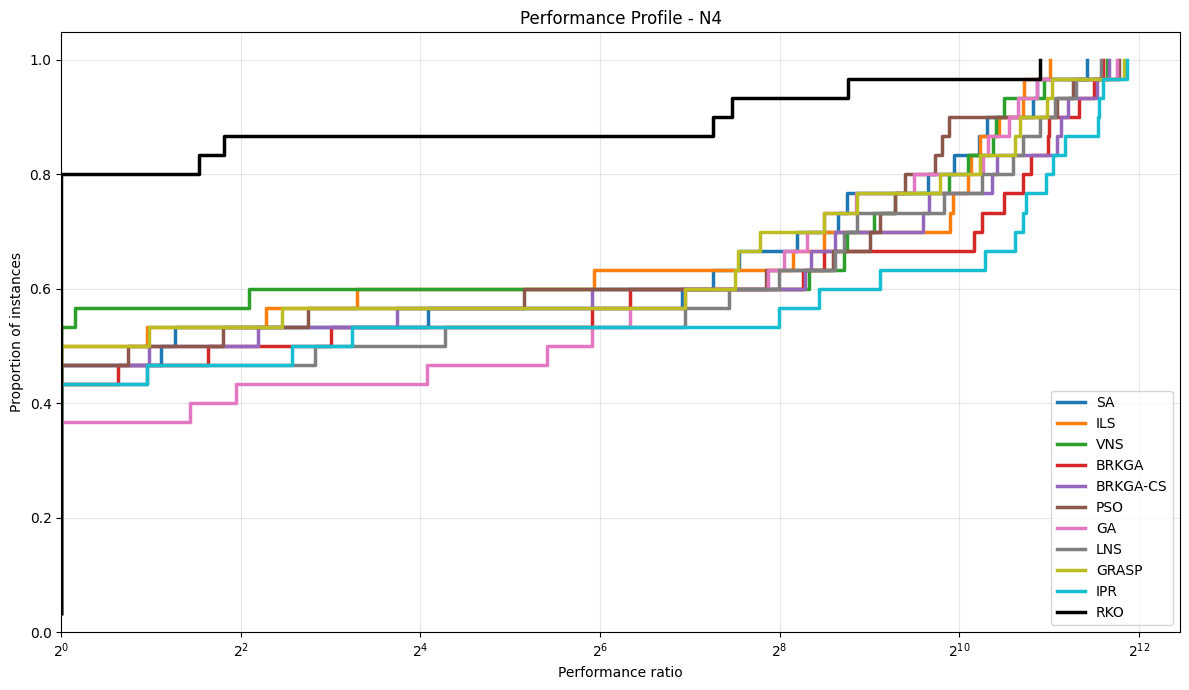

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("/content/Metaheuristicas_N4_Wil.csv")

algoritmos = [
    "SA", "ILS", "VNS", "BRKGA",
    "BRKGA-CS", "PSO", "GA", "LNS",
    "GRASP", "IPR", "RKO"
]

gaps = df[algoritmos].div(df["BKS"], axis=0)
gaps = (gaps - 1) * 100 + 0.001

ratios = gaps.div(gaps.min(axis=1), axis=0)

plt.figure(figsize=(12, 7))

cores = [
    "#1f77b4",  # SA
    "#ff7f0e",  # ILS
    "#2ca02c",  # VNS
    "#d62728",  # BRKGA
    "#9467bd",  # BRKGA-CS
    "#8c564b",  # PSO
    "#e377c2",  # GA
    "#7f7f7f",  # LNS
    "#bcbd22",  # GRASP
    "#17becf",  # IPR
    "#000000"   # RKO
]

for algoritmo, cor in zip(algoritmos, cores):
    x = np.sort(ratios[algoritmo])
    y = np.arange(1, len(x) + 1) / len(x)

    plt.step(x, y, where="post",
             label=algoritmo, linewidth=2.5,
             color=cor)

plt.xscale("log", base=2)
plt.xlabel("Performance ratio")
plt.ylabel("Proportion of instances")
plt.title("Performance Profile - N4")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xlim(left=1)
plt.ylim(bottom=0)
plt.tight_layout()
plt.show()

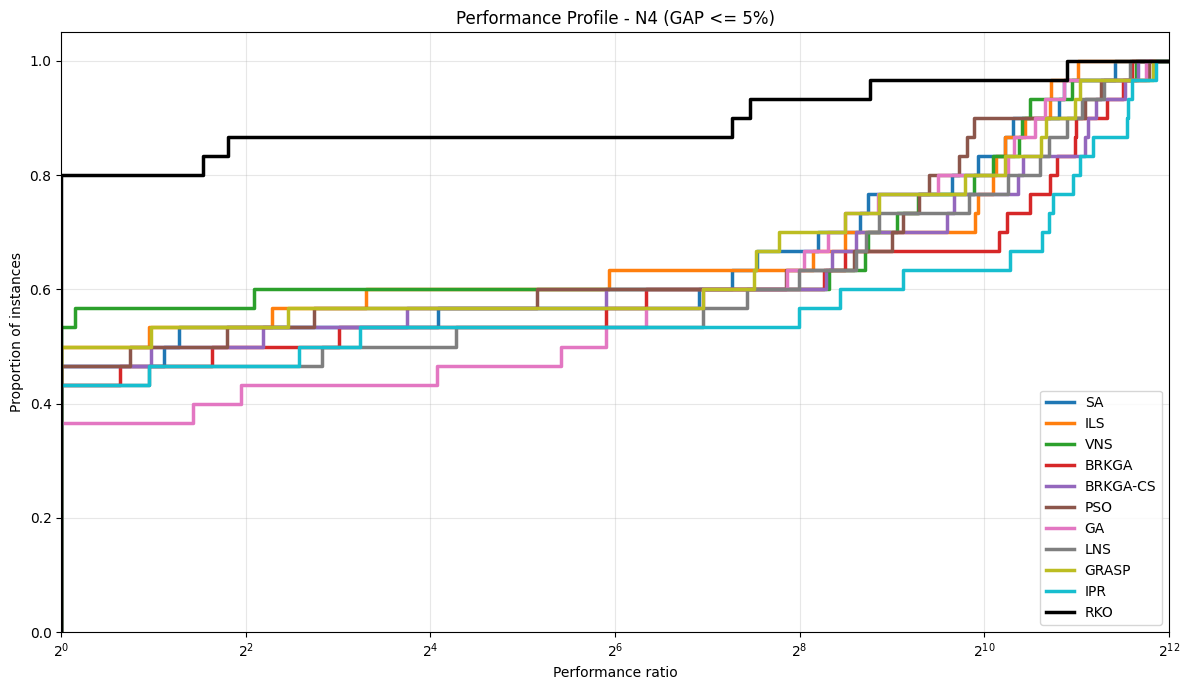

          Melhores (tau=1)  Dentro da tolerancia  Total
SA                      14                    30     30
ILS                     15                    30     30
VNS                     16                    30     30
BRKGA                   13                    30     30
BRKGA-CS                14                    30     30
PSO                     14                    30     30
GA                      11                    30     30
LNS                     13                    30     30
GRASP                   15                    30     30
IPR                     13                    30     30
RKO                     24                    30     30


<Figure size 640x480 with 0 Axes>

In [60]:
%run /content/PerformanceProfile_N3_Tolerancia.py

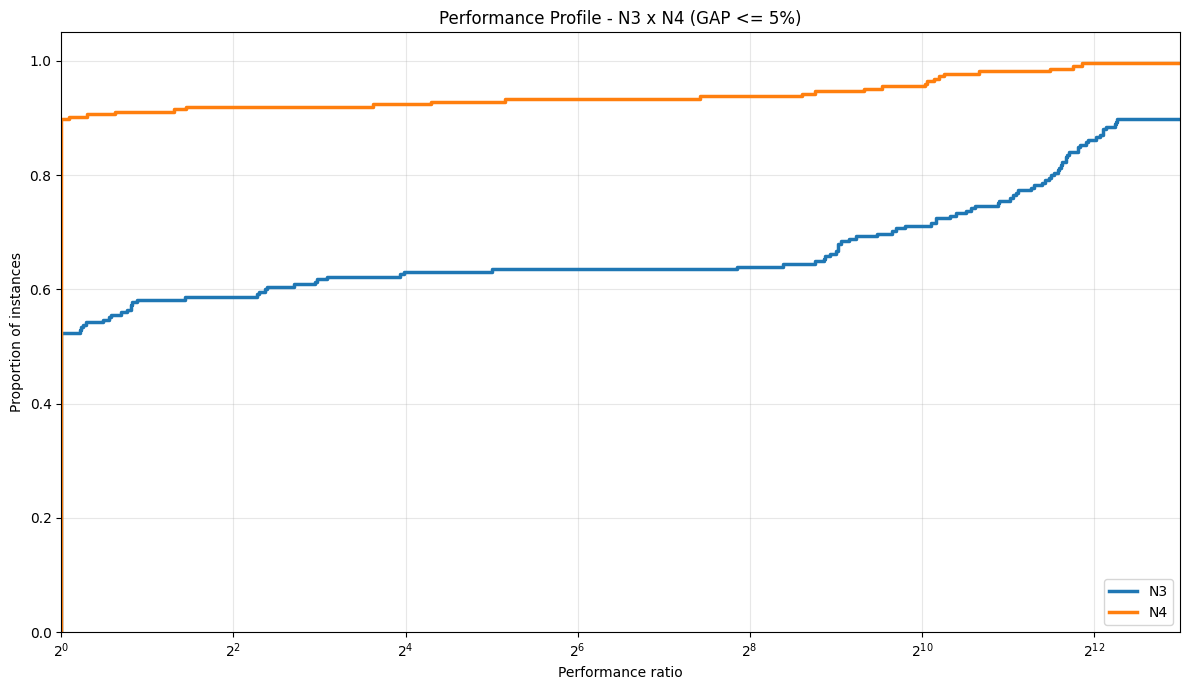

    Melhores (tau=1)  Dentro da tolerancia  Total
N3               118                   202    225
N4               202                   224    225


<Figure size 640x480 with 0 Axes>

In [55]:
%run /content/PerformanceProfile_N3_N4_Tolerancia.py

In [61]:
import pandas as pd
from scipy.stats import friedmanchisquare

df = pd.read_csv("/content/Metaheuristicas_N3_Wil.csv")

algoritmos = [
    "SA", "ILS", "VNS", "BRKGA",
    "BRKGA-CS", "PSO", "GA", "LNS",
    "GRASP", "IPR", "RKO"
]

estatistica, p_valor = friedmanchisquare(
    *[df[a] for a in algoritmos]
)

print("Estatística de Friedman:", estatistica)
print("p-valor:", p_valor)

ranking = df[algoritmos].rank(axis=1, ascending=True)
print("\nRanking médio:")
print(ranking.mean().sort_values())

Estatística de Friedman: 196.86243280907817
p-valor: 7.278010790452488e-37

Ranking médio:
VNS          3.400000
RKO          3.483333
ILS          3.566667
GRASP        3.616667
LNS          5.866667
GA           6.300000
SA           6.583333
BRKGA        7.166667
PSO          7.550000
BRKGA-CS     7.633333
IPR         10.833333
dtype: float64


In [62]:
df = pd.read_csv("/content/Metaheuristicas_N4_Wil.csv")

estatistica, p_valor = friedmanchisquare(
    *[df[a] for a in algoritmos]
)

print("Estatística de Friedman:", estatistica)
print("p-valor:", p_valor)

ranking = df[algoritmos].rank(axis=1, ascending=True)

print("\nRanking médio:")
print(ranking.mean().sort_values())

Estatística de Friedman: 46.95579847908754
p-valor: 9.61913112797557e-07

Ranking médio:
RKO         3.583333
VNS         5.266667
SA          5.566667
ILS         5.666667
GRASP       5.916667
PSO         6.033333
GA          6.383333
BRKGA-CS    6.466667
LNS         6.683333
BRKGA       6.716667
IPR         7.716667
dtype: float64


In [63]:
!pip install scikit-posthocs

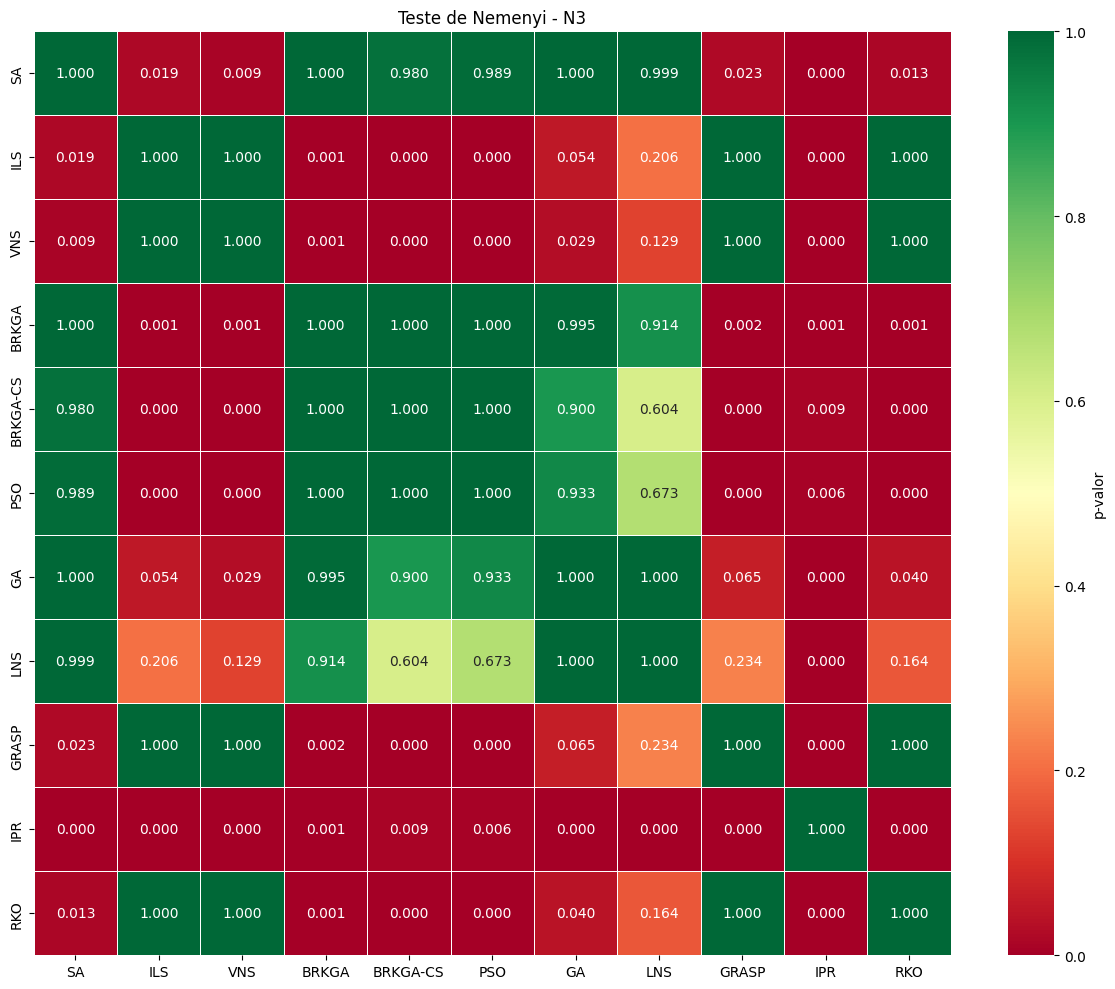

In [65]:
import scikit_posthocs as sp
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("/content/Metaheuristicas_N3_Wil.csv")

nemenyi = sp.posthoc_nemenyi_friedman(df[algoritmos])

nemenyi.index = algoritmos
nemenyi.columns = algoritmos

plt.figure(figsize=(12, 10))

sns.heatmap(
    nemenyi,
    annot=True,
    fmt=".3f",
    cmap="RdYlGn",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"label": "p-valor"}
)

plt.title("Teste de Nemenyi - N3")
plt.tight_layout()
plt.savefig("Nemenyi_N3.png", dpi=300, bbox_inches="tight")
plt.show()

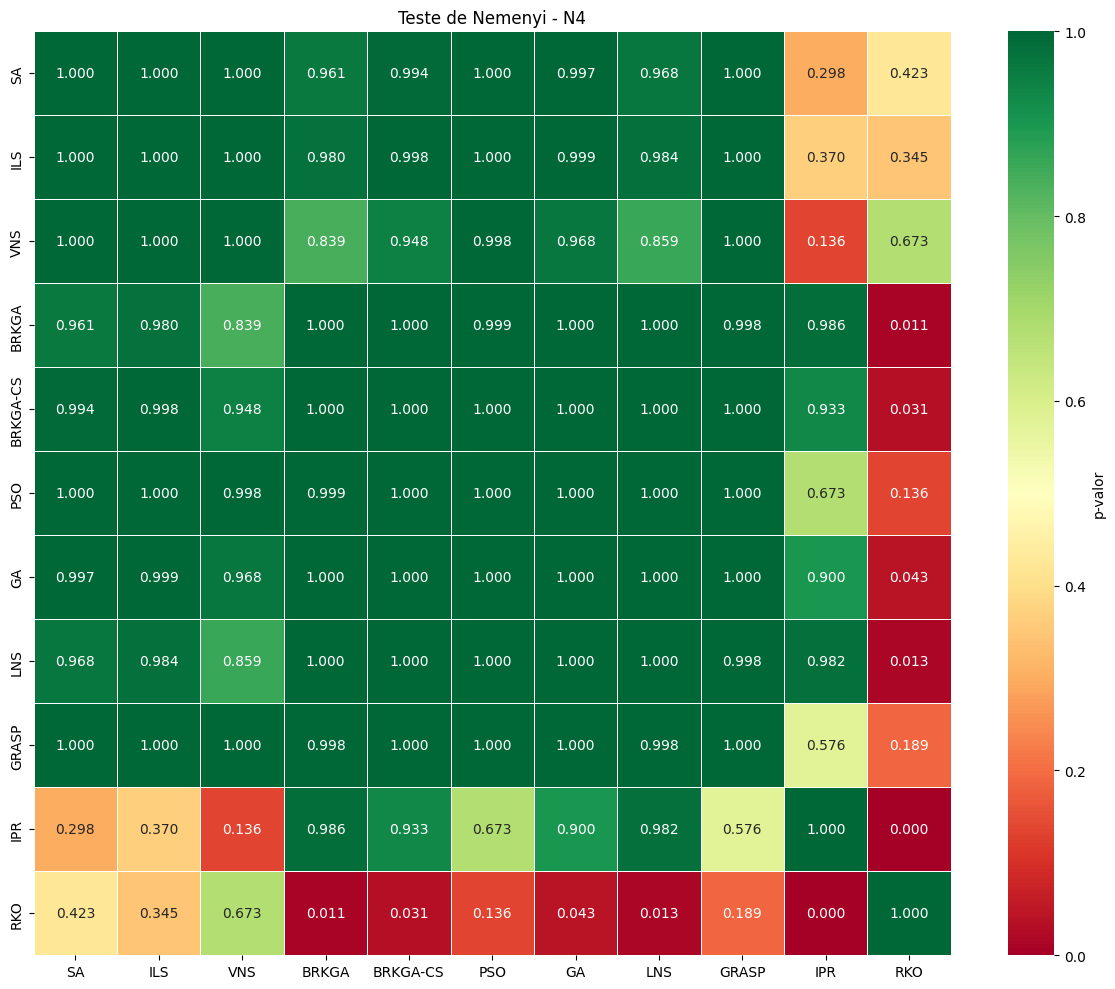

In [66]:
df = pd.read_csv("/content/Metaheuristicas_N4_Wil.csv")

nemenyi = sp.posthoc_nemenyi_friedman(df[algoritmos])

nemenyi.index = algoritmos
nemenyi.columns = algoritmos

plt.figure(figsize=(12, 10))

sns.heatmap(
    nemenyi,
    annot=True,
    fmt=".3f",
    cmap="RdYlGn",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"label": "p-valor"}
)

plt.title("Teste de Nemenyi - N4")
plt.tight_layout()
plt.savefig("Nemenyi_N4.png", dpi=300, bbox_inches="tight")
plt.show()